# ST-GCN-LSTM Crime Prediction Pipeline (Regression)

Predicting daily crime counts across Chicago census tracts using graph neural networks.

| Property | Value |
|----------|-------|
| Task | Regression (predict `crime_count`) |
| Spatial Unit | Census Tract |
| Temporal Unit | Daily |
| Time Period | 2021-2023 |
| Baselines | GCN, LSTM, CNN, CNN+LSTM |
| Main Model | ST-GCN-LSTM |

In [3]:
# Install PyTorch with CUDA 12.1 support (for Colab GPU)
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
# Install PyTorch Geometric and its dependencies for graph neural networks
!pip install torch-geometric
!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-2.5.0+cu121.html
# Install geospatial and visualization libraries
!pip install geopandas libpysal networkx seaborn tqdm

# Check setup
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Looking in indexes: https://download.pytorch.org/whl/cu121
  Using cached https://download-r2.pytorch.org/whl/torchvision-0.2.0-py2.py3-none-any.whl (48 kB)


ERROR: Could not find a version that satisfies the requirement torchaudio (from versions: none)

[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for torchaudio



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Looking in links: https://data.pyg.org/whl/torch-2.5.0+cu121.html
  Using cached torch_scatter-2.1.2.tar.gz (108 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached torch_sparse-0.6.18.tar.gz (209 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached torch_cluster-1.6.3.tar.gz (54 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached torch_spline_conv-1.2.2.tar.gz (25 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Running setup.py clean for torch-scatter
  Running setup.py clean for torch-sparse
  Running setup.py clean for torch-cluster
  Running setup.py clean for torch-spline-conv
Failed to build torch-scatter torch-sparse torch-cluster torch-spline-conv


  DEPRECATION: Building 'torch-scatter' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'torch-scatter'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  error: subprocess-exited-with-error
  
  python setup.py bdist_wheel did not run successfully.
  exit code: 1
  
  [43 lines of output]
  C:\Users\aremu\AppData\Local\Programs\Python\Python313\Lib\site-packages\setuptools\dist.py:759: SetuptoolsDeprecationWarning: License classifiers are deprecated.
  !!
  
          ********************************************************************************
          Please consider removing the following classifiers in favor of a SPDX license expression:
  
          License :: OSI 


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


PyTorch: 2.9.1+cpu
CUDA available: False


## 1. Environment Setup & Imports

In [5]:
# Standard libraries
import os, sys, pickle, json, requests, warnings
from pathlib import Path
from datetime import datetime
warnings.filterwarnings('ignore')  

# Data processing
import numpy as np
import pandas as pd
import geopandas as gpd  
from shapely.geometry import Point  
from tqdm.notebook import tqdm  

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# PyTorch Geometric
from torch_geometric.nn import GCNConv, GATConv  
from torch_geometric.data import Data  
from torch_geometric.data import Dataset as PyGDataset  
from torch_geometric.loader import DataLoader as PyGDataLoader  
from torch_geometric.utils import dense_to_sparse  

# Spatial weights
from libpysal.weights import KNN
# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Plotting
import networkx as nx  
import matplotlib.pyplot as plt
import seaborn as sns

# Output dirs
for d in ['data', 'data/plots', 'outputs', 'models']:
    os.makedirs(d, exist_ok=True)

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch: {torch.__version__}")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch: 2.9.1+cpu
Device: cpu


## 2. Data Processing Functions

Data loading and grid construction functions.

In [6]:
def load_census_tracts(url):
    """Download Chicago census tract boundaries."""
    # Read GeoJSON directly into a GeoDataFrame
    tracts = gpd.read_file(url)

    # Ensure WGS84
    if tracts.crs is None:
        tracts = tracts.set_crs(epsg=4326)
    elif tracts.crs.to_epsg() != 4326:
        tracts = tracts.to_crs(epsg=4326)

    # Assign sequential IDs
    tracts = tracts.reset_index(drop=True)
    tracts['GEOID'] = [str(i) for i in range(len(tracts))]

    # Pre-compute centroids
    tracts['centroid_lon'] = tracts.geometry.centroid.x
    tracts['centroid_lat'] = tracts.geometry.centroid.y
    return tracts


def load_crime_data(csv_path, tracts_gdf, start='2021-01-01', end='2023-12-31'):
    """Load crime CSV and spatially join to tracts."""
    # Read and clean
    df = pd.read_csv(csv_path)
    df.columns = [c.lower().replace(' ', '_') for c in df.columns]

    # Filter to study period
    df['date'] = pd.to_datetime(df['date'])
    df = df[(df['date'] >= start) & (df['date'] <= end)].copy()

    # Clean coordinates
    df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
    df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
    df = df.dropna(subset=['latitude', 'longitude']).copy()

    # Create point geometries
    gdf = gpd.GeoDataFrame(
        df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326"
    )

    # Spatial join
    joined = gpd.sjoin(gdf, tracts_gdf[['GEOID', 'geometry']], how='inner', predicate='within')
    return joined


def build_spatiotemporal_grid(joined, tracts_gdf, start='2021-01-01', end='2023-12-31'):
    """Build daily crime count grid (every tract x every date)."""
    # Count per tract per day
    joined['date_only'] = joined['date'].dt.date
    daily_counts = joined.groupby(['GEOID', 'date_only']).size().reset_index(name='crime_count')

    # Full grid
    all_dates = pd.date_range(start, end, freq='D')
    all_tracts = sorted(tracts_gdf['GEOID'].unique())
    idx = pd.MultiIndex.from_product([all_tracts, all_dates.date], names=['GEOID', 'date_only'])
    ts = pd.DataFrame(index=idx).reset_index()

    # Fill missing = 0
    ts = ts.merge(daily_counts, on=['GEOID', 'date_only'], how='left')
    ts['crime_count'] = ts['crime_count'].fillna(0).astype(int)
    ts['date'] = pd.to_datetime(ts['date_only'])

    # Validate completeness
    tracts_per_date = ts.groupby('date')['GEOID'].nunique()
    assert tracts_per_date.min() == len(all_tracts), "Grid incomplete: some dates have fewer tracts"
    return ts

## 3. Feature Engineering

Since the model already sees 30 days of raw crime counts, any lag or rolling average features would be redundant — the model can figure out those patterns on its own. So we just use `crime_count` (F=1).

In [7]:
def engineer_features(ts):
    """Add time columns for EDA. Model features = crime_count only."""
    # For EDA plots only
    ts['month'] = ts['date'].dt.month
    ts['day_of_week'] = ts['date'].dt.dayofweek
    return ts


# Only crime_count — lags and rolling stats are derivable from the lookback window
FEATURE_COLS = ['crime_count']
NUM_FEATURES = len(FEATURE_COLS)  # = 1

# Default lookback window
SEQ_LEN = 30

## 4. Run Data Pipeline

**Note:** The crime dataset (`Chicago_Crimes_2001_to_Present.csv`, ~1.9 GB) must be downloaded separately from the [Chicago Data Portal](https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2).

In [8]:
# Step 1: Load census tracts from Chicago Data Portal GeoJSON API
census_url = "https://data.cityofchicago.org/resource/4hp8-2i8z.geojson?$limit=50000"
chicago_tracts = load_census_tracts(census_url)
print(f"Census Tracts loaded: {len(chicago_tracts)}")

# Step 2: Load crime CSV and spatially join each crime to its census tract
joined = load_crime_data('C:\Chicago_Data\Chicago_Crimes_2001_to_Present.csv', chicago_tracts)
print(f"Crime records matched to tracts: {len(joined):,}")
print(f"Tracts with at least one crime: {joined['GEOID'].nunique()}")

# Step 3: Build complete spatio-temporal grid (878 tracts x 1096 days)
ts = build_spatiotemporal_grid(joined, chicago_tracts)
print(f"Grid shape: {ts.shape}")
print(f"Spatial units: {ts['GEOID'].nunique()} tracts")
print(f"Temporal units: {ts['date'].nunique()} days")

# Step 4: Add crime_count features
ts = engineer_features(ts)
print(f"Features ({NUM_FEATURES}): {FEATURE_COLS}")

Census Tracts loaded: 878
Crime records matched to tracts: 696,262
Tracts with at least one crime: 873
Grid shape: (961410, 4)
Spatial units: 878 tracts
Temporal units: 1095 days
Features (1): ['crime_count']


## 5. Exploratory Data Analysis

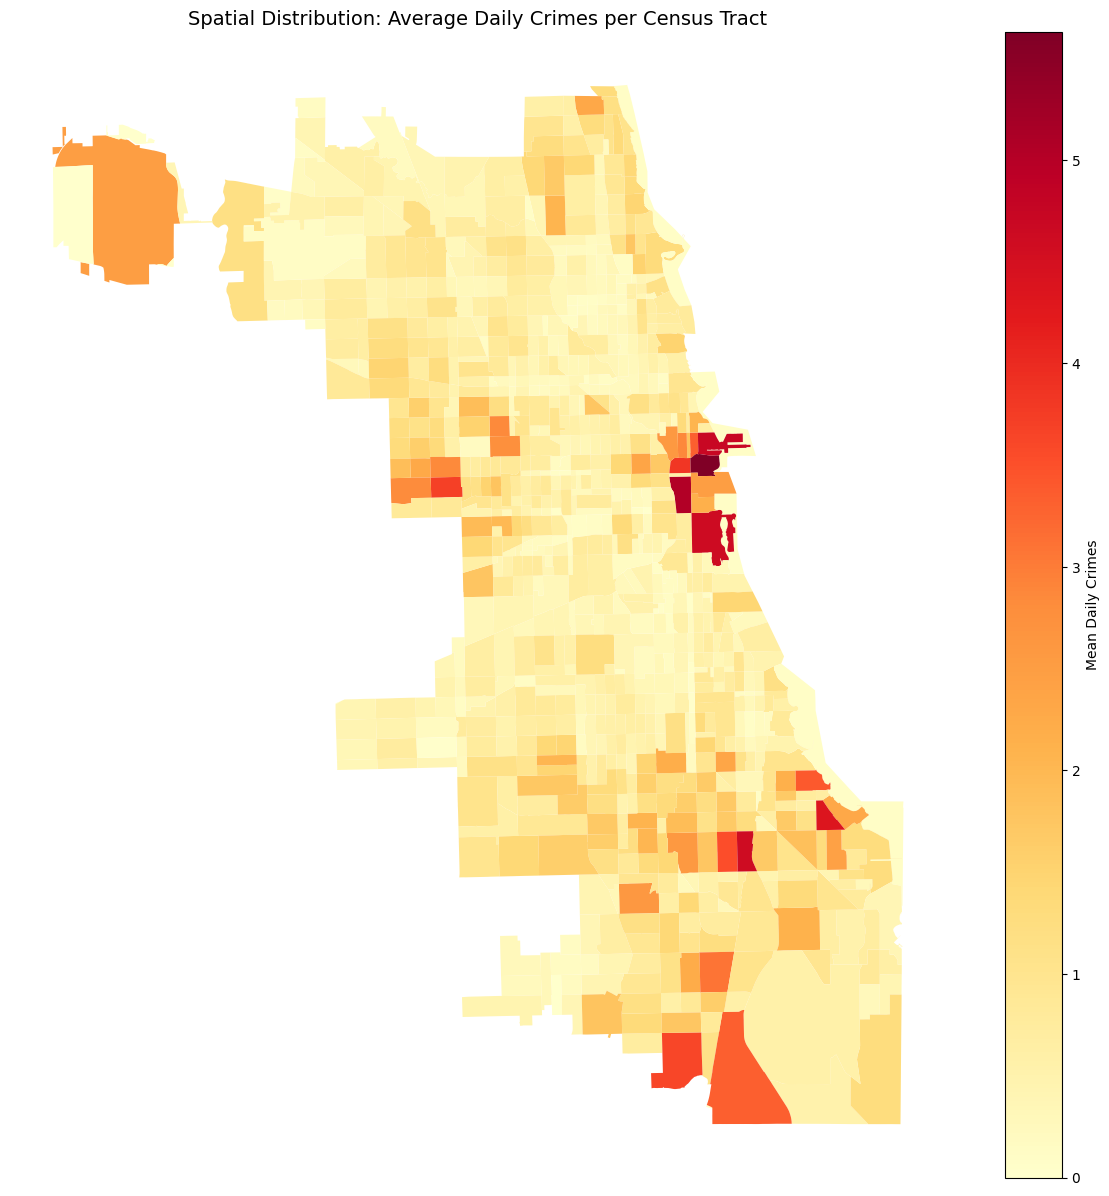

In [9]:
# Compute average daily crime count per tract for spatial visualization
mean_crimes = ts.groupby('GEOID')['crime_count'].mean().reset_index()
viz = chicago_tracts.merge(mean_crimes, on='GEOID', how='left')

# Plot choropleth map: darker colors indicate higher average daily crime counts
fig, ax = plt.subplots(figsize=(12, 12))
viz.plot(column='crime_count', legend=True, cmap='YlOrRd', ax=ax,
         legend_kwds={'label': 'Mean Daily Crimes'})
ax.set_title('Spatial Distribution: Average Daily Crimes per Census Tract', fontsize=14)
ax.axis('off')  # Hide axis for cleaner map
plt.tight_layout()
plt.savefig('data/plots/spatial_distribution.png', dpi=300)
plt.show()

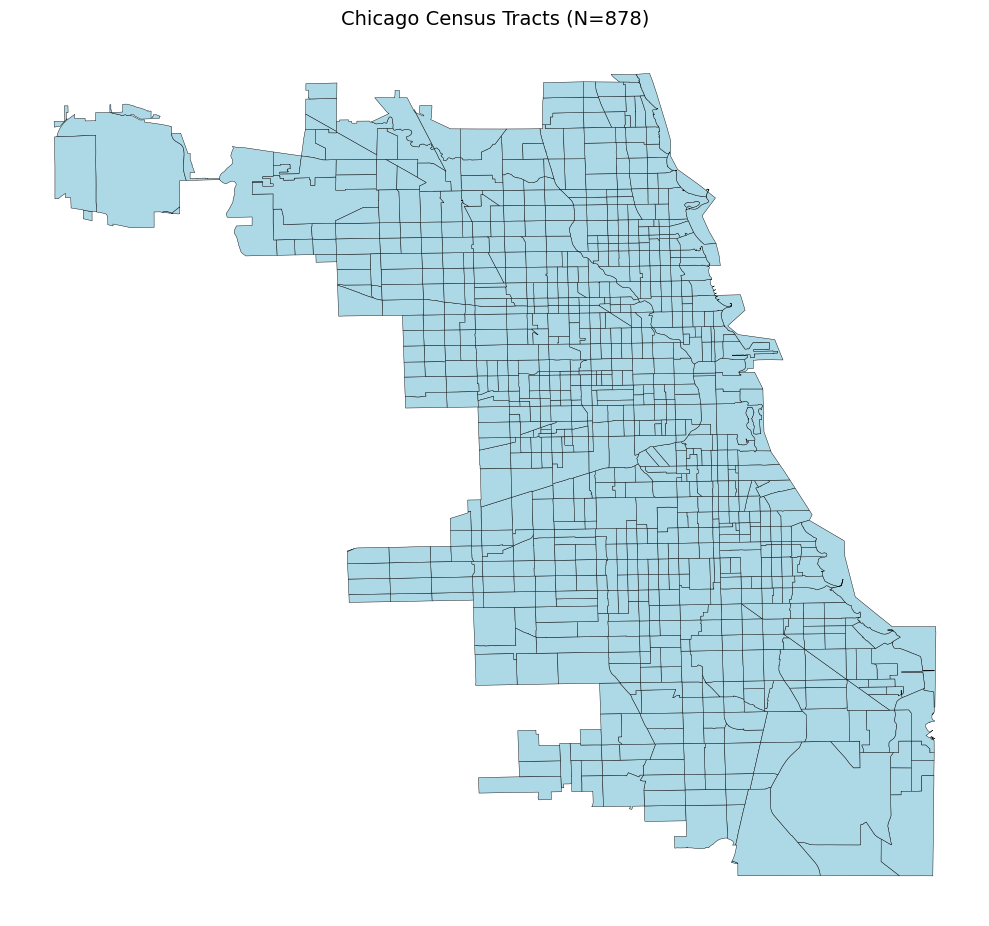

In [11]:
# Plot census tract boundaries to visualize the spatial units
fig, ax = plt.subplots(figsize=(10, 12))
chicago_tracts.plot(ax=ax, edgecolor='black', linewidth=0.3, facecolor='lightblue', aspect=1)
ax.set_title(f'Chicago Census Tracts (N={len(chicago_tracts)})', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.savefig('data/plots/census_tracts.png', dpi=300)
plt.show()

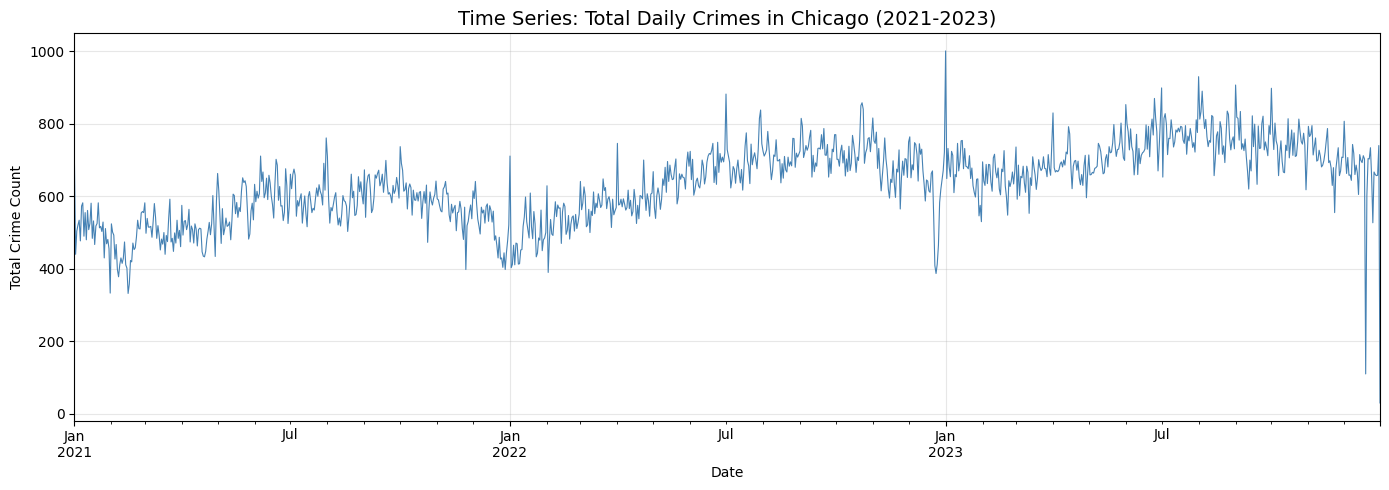

In [12]:
# Aggregate all tracts to get total daily crimes across the whole city
daily_total = ts.groupby('date')['crime_count'].sum()

# Plot the city-wide crime time series to identify trends and seasonality
fig, ax = plt.subplots(figsize=(14, 5))
daily_total.plot(ax=ax, linewidth=0.8, color='steelblue')
ax.set_title('Time Series: Total Daily Crimes in Chicago (2021-2023)', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Total Crime Count')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('data/plots/time_series.png', dpi=300)
plt.show()

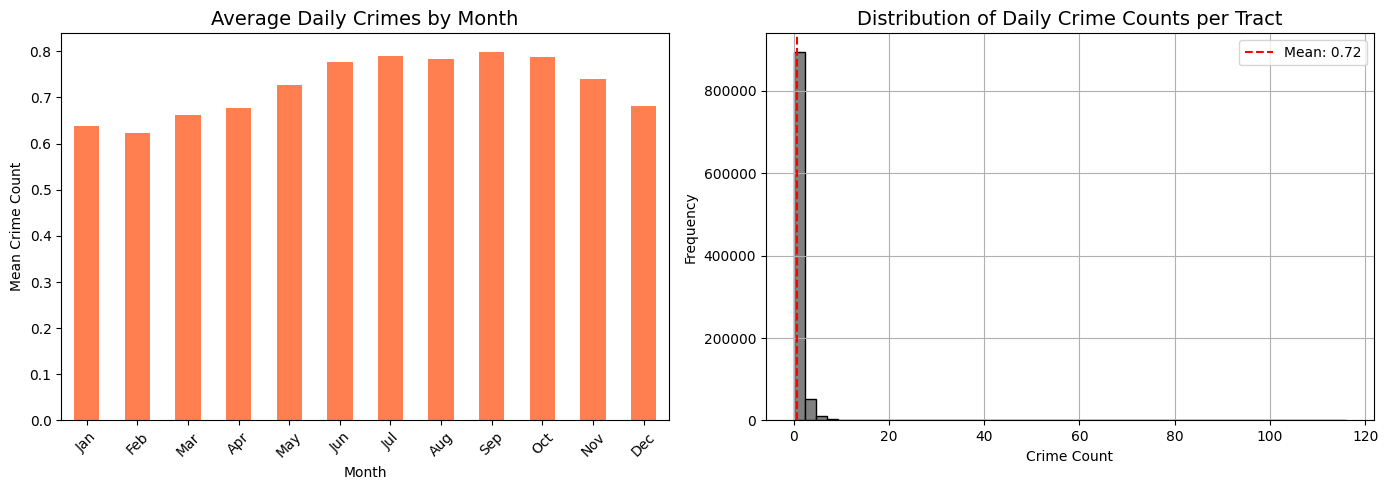

In [11]:
# Create side-by-side plots for monthly pattern and distribution analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: average crimes by month (shows seasonal patterns)
ts.groupby('month')['crime_count'].mean().plot(kind='bar', ax=axes[0], color='coral')
axes[0].set_title('Average Daily Crimes by Month', fontsize=14)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Mean Crime Count')
axes[0].set_xticklabels(
    ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45
)

# Right plot: histogram of daily crime counts per tract (shows data distribution)
ts['crime_count'].hist(bins=50, ax=axes[1], color='gray', edgecolor='black')
axes[1].set_title('Distribution of Daily Crime Counts per Tract', fontsize=14)
axes[1].set_xlabel('Crime Count')
axes[1].set_ylabel('Frequency')
# Add vertical line at the mean to show central tendency
axes[1].axvline(ts['crime_count'].mean(), color='red', linestyle='--',
                label=f"Mean: {ts['crime_count'].mean():.2f}")
axes[1].legend()

plt.tight_layout()
plt.savefig('data/plots/eda_monthly_histogram.png', dpi=150)
plt.show()

In [12]:
# Summary statistics for the sole model feature (crime_count)
print('Crime Count Statistics:')
print(ts['crime_count'].describe())
print(f'\nZero-crime tract-days: {(ts["crime_count"] == 0).sum():,} '
      f'({(ts["crime_count"] == 0).mean()*100:.1f}%)')
print(f'Max daily crime count: {ts["crime_count"].max()}')

Crime Count Statistics:
count    961410.000000
mean          0.724209
std           1.157385
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max         116.000000
Name: crime_count, dtype: float64

Zero-crime tract-days: 550,979 (57.3%)
Max daily crime count: 116


---
## 6. Graph Construction (KNN)

In [13]:
def construct_spatial_graph(tracts_gdf, k=5, sigma=1.0):
    """
    Build a K-Nearest Neighbors spatial graph from census tract centroids.
    Edge weights are computed using a Gaussian kernel over Euclidean distances.

    Args:
        tracts_gdf: GeoDataFrame with centroid_lon and centroid_lat columns
        k: number of nearest neighbors per node
        sigma: bandwidth parameter for Gaussian kernel (controls weight decay)

    Returns:
        edge_index: [2, E] tensor of directed edges in COO format
        edge_weight: [E] tensor of Gaussian-weighted edge strengths
        coords: [N, 2] array of centroid coordinates
        n: number of nodes (census tracts)
    """
    # Sort for consistent ordering
    tracts_gdf = tracts_gdf.sort_values('GEOID').reset_index(drop=True)
    n = len(tracts_gdf)

    # Centroid coords
    coords = np.column_stack([tracts_gdf['centroid_lon'].values,
                              tracts_gdf['centroid_lat'].values])

    # KNN adjacency
    w = KNN.from_array(coords, k=k)
    adj_matrix = w.full()[0]  # Full dense adjacency matrix [N, N]

    # Convert to COO format
    adj_tensor = torch.FloatTensor(adj_matrix)
    edge_index, _ = dense_to_sparse(adj_tensor)

    # Gaussian edge weights
    row, col = edge_index
    distances = np.linalg.norm(coords[row] - coords[col], axis=1)
    edge_weight = torch.FloatTensor(np.exp(-distances ** 2 / (2 * sigma ** 2)))

    print(f"Graph: {n} nodes, {edge_index.size(1)} edges")
    return edge_index, edge_weight, coords, n


# Build spatial graph
edge_index, edge_weight, tract_coords, NUM_NODES = construct_spatial_graph(chicago_tracts, k=5)

assert edge_index.max().item() == NUM_NODES - 1, "Edge index does not match node count"

Graph: 878 nodes, 4390 edges


## 7. Graph Visualization (NetworkX)

`G_viz` is only for plotting. Models use `edge_index` and `edge_weight` tensors directly.

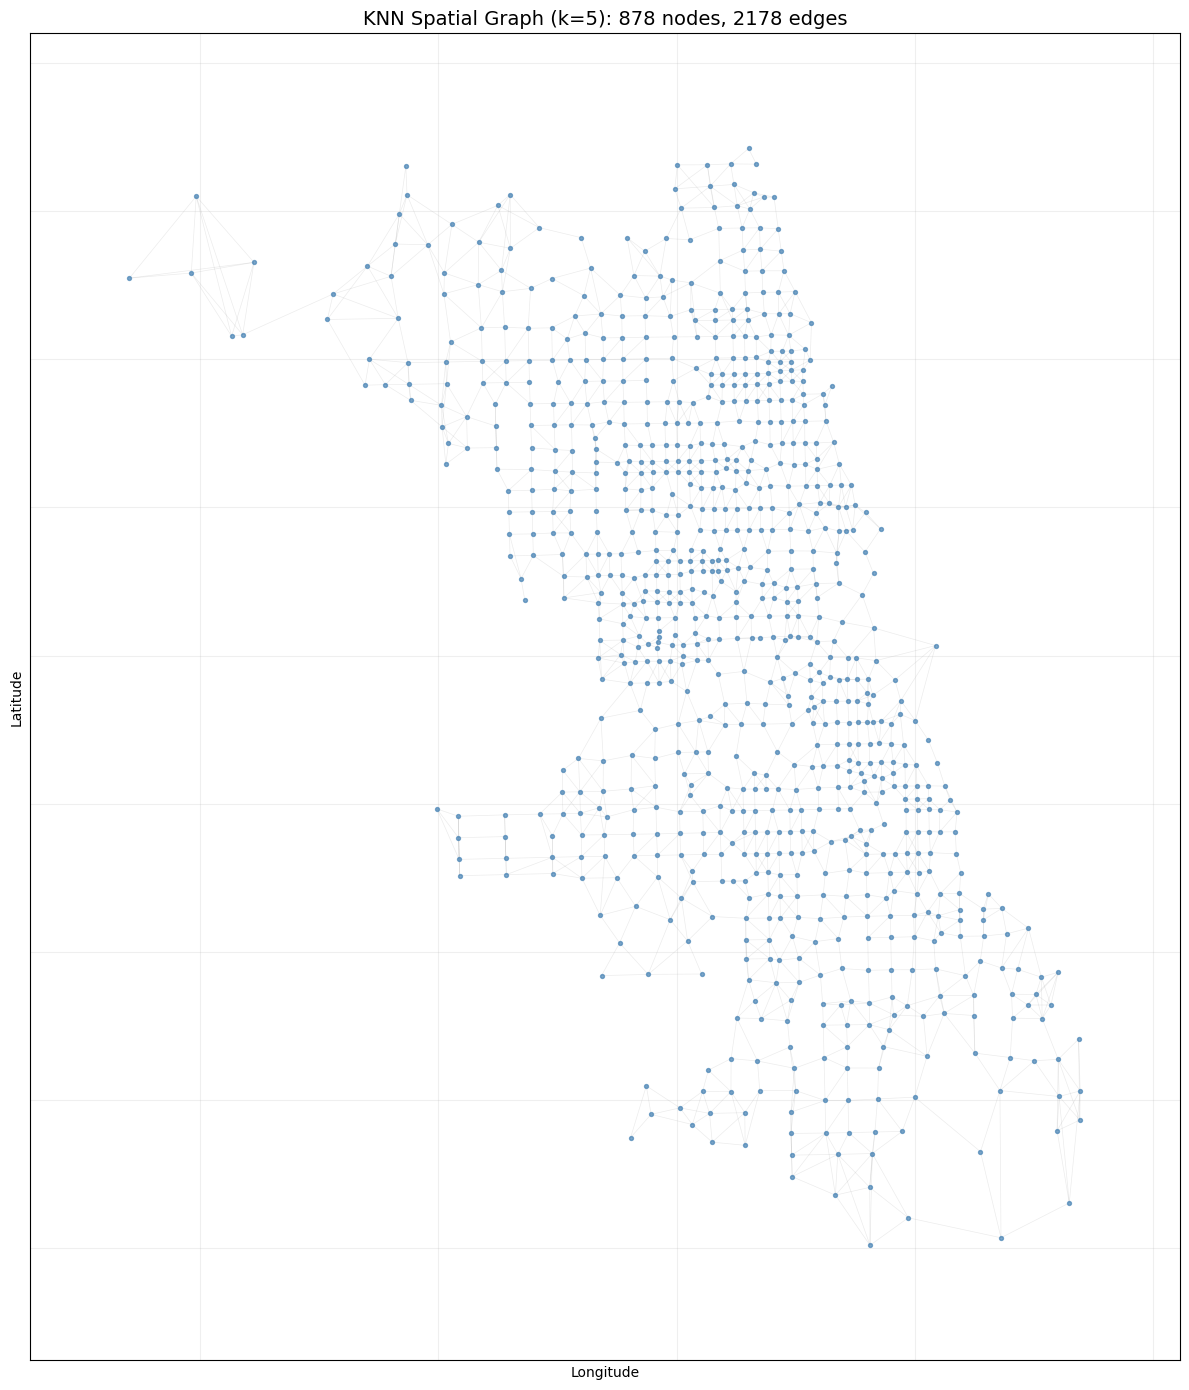

In [14]:
# NetworkX graph for plotting only
G_viz = nx.Graph()
sorted_tracts = chicago_tracts.sort_values('GEOID').reset_index(drop=True)


for i in range(len(sorted_tracts)):
    G_viz.add_node(i)

# Undirected edges
src, dst = edge_index[0].numpy(), edge_index[1].numpy()
for s, d in zip(src, dst):
    if s < d:
        G_viz.add_edge(int(s), int(d))

# Geographic positions
pos = {i: (tract_coords[i, 0], tract_coords[i, 1]) for i in range(len(sorted_tracts))}


fig, ax = plt.subplots(figsize=(12, 14))
nx.draw_networkx_edges(G_viz, pos, ax=ax, alpha=0.15, edge_color='gray', width=0.5)
nx.draw_networkx_nodes(G_viz, pos, ax=ax, node_size=8, node_color='steelblue', alpha=0.7)
ax.set_title(f'KNN Spatial Graph (k=5): {G_viz.number_of_nodes()} nodes, '
             f'{G_viz.number_of_edges()} edges', fontsize=14)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('data/plots/knn_graph_networkx.png', dpi=150)
plt.show()

## 8. PyTorch Geometric Dataset & Train/Val/Test Split

Chronological split to avoid data leakage:
- **Train:** 2021-01-01 to 2023-10-31 (34 months)
- **Validation:** 2023-11-01 to 2023-11-30 (1 month)
- **Test:** 2023-12-01 to 2023-12-31 (1 month)

In [15]:
class CrimeGraphDataset(PyGDataset):
    """
    PyTorch Geometric dataset that produces full-graph samples.
    Each sample contains:
        x:           [N, T, F] node features for T lookback days
        y:           [N] target crime counts for the prediction day
        edge_index:  [2, E] graph structure
        edge_weight: [E] edge weights
    """

    def __init__(self, full_df, tracts_gdf, edge_index, edge_weight,
                 sequence_length=30, feature_cols=None,
                 start_date=None, end_date=None):
        super().__init__()
        # Sort for consistent access
        self.data_df = full_df.sort_values(['GEOID', 'date']).reset_index(drop=True)
        self.edge_index = edge_index
        self.edge_weight = edge_weight
        self.sequence_length = sequence_length
        self.feature_cols = feature_cols or FEATURE_COLS


        self.sorted_tracts = sorted(self.data_df['GEOID'].unique())
        self.num_nodes = len(self.sorted_tracts)
        self.dates = sorted(self.data_df['date'].unique())

        # Cache feature matrices
        self.date_data = {}
        for date in self.dates:
            day_data = self.data_df[self.data_df['date'] == date].sort_values('GEOID')
            self.date_data[date] = day_data[self.feature_cols].values

        # Valid prediction dates (need enough lookback)
        self.valid_indices = []
        for i in range(self.sequence_length, len(self.dates)):
            d = self.dates[i]

            if start_date and d < pd.Timestamp(start_date):
                continue
            if end_date and d >= pd.Timestamp(end_date):
                continue
            self.valid_indices.append(i)

    def len(self):

        return len(self.valid_indices)

    def get(self, idx):


        target_date_idx = self.valid_indices[idx]
        target_date = self.dates[target_date_idx]

        # Lookback window
        seq_dates = self.dates[target_date_idx - self.sequence_length:target_date_idx]

        # Stack and permute to [N, T, F]
        node_features_seq = [self.date_data[d] for d in seq_dates]
        x = torch.FloatTensor(np.array(node_features_seq)).permute(1, 0, 2)

        # Ground truth
        target_data = self.data_df[self.data_df['date'] == target_date].sort_values('GEOID')
        y = torch.FloatTensor(target_data['crime_count'].values)


        assert x.size(0) == self.num_nodes, f"Node mismatch: {x.size(0)} vs {self.num_nodes}"
        return Data(x=x, edge_index=self.edge_index, edge_weight=self.edge_weight, y=y)

In [16]:
# Create the three temporal splits using date boundaries
train_dataset = CrimeGraphDataset(
    ts, chicago_tracts, edge_index, edge_weight,
    sequence_length=SEQ_LEN, end_date='2023-11-01'
)
val_dataset = CrimeGraphDataset(
    ts, chicago_tracts, edge_index, edge_weight,
    sequence_length=SEQ_LEN, start_date='2023-11-01', end_date='2023-12-01'
)
test_dataset = CrimeGraphDataset(
    ts, chicago_tracts, edge_index, edge_weight,
    sequence_length=SEQ_LEN, start_date='2023-12-01'
)

print(f"Train: {len(train_dataset)} samples")
print(f"Val:   {len(val_dataset)} samples")
print(f"Test:  {len(test_dataset)} samples")
print(f"Nodes per sample: {train_dataset.num_nodes}")

# Verify that the first sample has the expected tensor shapes
sample = train_dataset[0]
print(f"Sample x shape: {sample.x.shape}")   # Expected: [N, SEQ_LEN, NUM_FEATURES]
print(f"Sample y shape: {sample.y.shape}")   # Expected: [N]

# Create PyG data loaders (batch_size=1 because each sample is already the full graph)
train_loader = PyGDataLoader(train_dataset, batch_size=1, shuffle=True, num_workers=0)
val_loader = PyGDataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=0)

Train: 1004 samples
Val:   30 samples
Test:  31 samples
Nodes per sample: 878
Sample x shape: torch.Size([878, 30, 1])
Sample y shape: torch.Size([878])


## 9. Training & Evaluation Utilities

In [17]:
def train_epoch(model, loader, optimizer, criterion, device):
    """One training epoch."""
    model.train()  # Set model to training mode (enables dropout, etc.)
    total_loss = 0
    all_preds, all_labels = [], []

    for batch in tqdm(loader, desc="Training"):
        optimizer.zero_grad()  # Clear previous gradients


        x = batch.x.to(device)
        edge_index = batch.edge_index.to(device)
        edge_weight = batch.edge_weight.to(device) if batch.edge_weight is not None else None
        y = batch.y.to(device).float()


        output = model(x, edge_index, edge_weight)
        loss = criterion(output, y)

        # Backward pass + clip gradients
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()


        total_loss += loss.item()
        all_preds.extend(output.detach().cpu().numpy())
        all_labels.extend(y.cpu().numpy())

    avg_loss = total_loss / len(loader)
    mae = mean_absolute_error(all_labels, all_preds)
    rmse = np.sqrt(mean_squared_error(all_labels, all_preds))
    return avg_loss, mae, rmse


@torch.no_grad()  # Disable gradient computation during evaluation for speed
def evaluate(model, loader, criterion, device):
    """Evaluate on a dataset."""
    model.eval()  # Set model to evaluation mode (disables dropout, etc.)
    total_loss = 0
    all_preds, all_labels = [], []

    for batch in tqdm(loader, desc="Evaluating"):
        x = batch.x.to(device)
        edge_index = batch.edge_index.to(device)
        edge_weight = batch.edge_weight.to(device) if batch.edge_weight is not None else None
        y = batch.y.to(device).float()

        output = model(x, edge_index, edge_weight)
        loss = criterion(output, y)

        total_loss += loss.item()
        all_preds.extend(output.cpu().numpy())
        all_labels.extend(y.cpu().numpy())


    avg_loss = total_loss / len(loader)
    preds, labels = np.array(all_preds), np.array(all_labels)
    mae = mean_absolute_error(labels, preds)
    rmse = np.sqrt(mean_squared_error(labels, preds))
    r2 = r2_score(labels, preds)
    return avg_loss, mae, rmse, r2, preds, labels


def train_model(model, train_loader, val_loader, name,
                epochs=50, lr=0.001, patience=15, loss_fn='SmoothL1Loss'):
    """
    Full training loop with early stopping and model checkpointing.

    Args:
        model: PyTorch model to train
        train_loader: training data loader
        val_loader: validation data loader
        name: model name (used for checkpoint filename)
        epochs: maximum number of training epochs
        lr: initial learning rate for Adam optimizer
        patience: number of epochs without improvement before early stopping
        loss_fn: 'SmoothL1Loss' (robust to outliers) or 'MSELoss' (penalizes large errors)
    """
    model = model.to(device)

    # Loss function
    if loss_fn == 'MSELoss':
        criterion = nn.MSELoss()
    else:
        criterion = nn.SmoothL1Loss()

    # Optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    # LR scheduler
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=lr/100)

    best_val_mae = float('inf')
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': [], 'val_mae': []}

    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"Loss function: {loss_fn}")
    print(f"{'='*60}")

    for epoch in range(1, epochs + 1):

        train_loss, train_mae, _ = train_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_mae, val_rmse, val_r2, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()  # Update learning rate


        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_mae'].append(val_mae)


        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoch {epoch:3d} | Train MAE: {train_mae:.4f} | "
                  f"Val MAE: {val_mae:.4f} | Val RMSE: {val_rmse:.4f} | Val R2: {val_r2:.4f}")

        # Early stopping
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            patience_counter = 0
            torch.save(model.state_dict(), f'models/{name}_best.pt')
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    # Load best weights
    model.load_state_dict(torch.load(f'models/{name}_best.pt', weights_only=True))
    print(f"Best Val MAE: {best_val_mae:.4f}")
    return model, history

---
## 10. Baseline 1 -- GCN Only

| | Shape |
|---|---|
| **Input x** | `[N, T, F]` -- uses only last timestep `x[:, -1, :]` -> `[N, F]` |
| **Output** | `[N]` -- predicted crime count per tract |

GCN captures spatial dependencies via neighbor aggregation but ignores temporal history.

In [29]:
class GCNRegressor(nn.Module):
    """GCN baseline (spatial only)."""

    def __init__(self, node_features, hidden=64, dropout=0.3):
        super().__init__()
        # Two GCN layers
        self.conv1 = GCNConv(node_features, hidden)
        self.conv2 = GCNConv(hidden, hidden)
        # LayerNorm (stable with batch_size=1)
        self.ln1 = nn.LayerNorm(hidden)
        self.ln2 = nn.LayerNorm(hidden)
        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(hidden, 1)

    def forward(self, x, edge_index, edge_weight=None):
        # Use last timestep only
        x_last = x[:, -1, :]  # Shape: [N, F]


        h = F.relu(self.ln1(self.conv1(x_last, edge_index, edge_weight)))
        h = self.dropout(h)

        h = F.relu(self.ln2(self.conv2(h, edge_index, edge_weight)))
        h = self.dropout(h)

        return self.fc(h).squeeze(-1)


# Train the GCN baseline
gcn_model = GCNRegressor(node_features=NUM_FEATURES)
gcn_model, gcn_history = train_model(
    gcn_model, train_loader, val_loader, 'gcn_baseline', epochs=50, patience=15
)


Training: gcn_baseline
Parameters: 4,609
Loss function: SmoothL1Loss


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch   1 | Train MAE: 0.7439 | Val MAE: 0.7874 | Val RMSE: 1.1615 | Val R2: 0.0740


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

... (54 outputs left out)

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Early stopping at epoch 28
Best Val MAE: 0.7851


## 11. Baseline 2 -- LSTM Only

| | Shape |
|---|---|
| **Input x** | `[N, T, F]` -- each census tract processed independently |
| **Output** | `[N]` -- predicted crime count per tract |

LSTM captures temporal patterns in each tract's history but ignores spatial neighbors.

In [31]:
class LSTMRegressor(nn.Module):
    """LSTM baseline (temporal only)."""

    def __init__(self, input_features, hidden_size=128, num_layers=2, dropout=0.3):
        super().__init__()
        # 2-layer LSTM
        self.lstm = nn.LSTM(
            input_size=input_features, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.fc1 = nn.Linear(hidden_size, 64)
        self.fc2 = nn.Linear(64, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index=None, edge_weight=None):
        # LSTM processes each node's sequence independently
        _, (hn, _) = self.lstm(x)

        out = F.relu(self.fc1(self.dropout(hn[-1])))
        return self.fc2(self.dropout(out)).squeeze(-1)


# Train the LSTM baseline
lstm_model = LSTMRegressor(input_features=NUM_FEATURES)
lstm_model, lstm_history = train_model(
    lstm_model, train_loader, val_loader, 'lstm_baseline', epochs=50, patience=15
)


Training: lstm_baseline
Parameters: 207,489
Loss function: SmoothL1Loss


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch   1 | Train MAE: 0.6588 | Val MAE: 0.6964 | Val RMSE: 0.9792 | Val R2: 0.3420


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

... (30 outputs left out)

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Early stopping at epoch 17
Best Val MAE: 0.6861


## 12. Baseline 3 -- CNN Only

| | Shape |
|---|---|
| **Input x** | `[N, T, F]` -- each census tract processed independently |
| **Output** | `[N]` -- predicted crime count per tract |

1D-CNN extracts local temporal patterns via convolution over the time axis. Uses adaptive pooling to support any sequence length T.

In [33]:
class CNNRegressor(nn.Module):
    """
    1D-CNN baseline (temporal only, local patterns).
    Uses AdaptiveAvgPool1d instead of fixed MaxPool1d so it works
    with any sequence length T (including T=1 in the window sweep).
    """

    def __init__(self, input_features, channels=[32, 64, 128], dropout=0.3):
        super().__init__()
        # 1D conv layers
        self.conv1 = nn.Conv1d(input_features, channels[0], kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(channels[0], channels[1], kernel_size=3, padding=1)
        self.conv3 = nn.Conv1d(channels[1], channels[2], kernel_size=3, padding=1)
        # Adaptive pool handles any sequence length
        self.adaptive_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)

        self.fc1 = nn.Linear(channels[2], 64)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x, edge_index=None, edge_weight=None):
        # [N, T, F] -> [N, F, T]
        h = x.permute(0, 2, 1)

        h = F.relu(self.conv1(h))
        h = F.relu(self.conv2(h))
        h = F.relu(self.conv3(h))

        h = self.adaptive_pool(h).squeeze(-1)  # Shape: [N, channels[-1]]

        out = F.relu(self.fc1(self.dropout(h)))
        return self.fc2(self.dropout(out)).squeeze(-1)


# Train the CNN baseline
cnn_model = CNNRegressor(input_features=NUM_FEATURES)
cnn_model, cnn_history = train_model(
    cnn_model, train_loader, val_loader, 'cnn_baseline', epochs=50, patience=15
)


Training: cnn_baseline
Parameters: 39,361
Loss function: SmoothL1Loss


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch   1 | Train MAE: 0.6548 | Val MAE: 0.6974 | Val RMSE: 0.9729 | Val R2: 0.3504


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

... (43 outputs left out)

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Early stopping at epoch 23
Best Val MAE: 0.6905


## 13. Baseline 4 -- CNN+LSTM

| | Shape |
|---|---|
| **Input x** | `[N, T, F]` -- each census tract processed independently |
| **Output** | `[N]` -- predicted crime count per tract |

CNN extracts local temporal features, then LSTM captures longer-range temporal dependencies.

In [35]:
class CNNLSTMRegressor(nn.Module):
    """CNN+LSTM baseline."""

    def __init__(self, input_features, cnn_channels=[32, 64], lstm_hidden=128, dropout=0.3):
        super().__init__()
        # CNN layers
        self.conv1 = nn.Conv1d(input_features, cnn_channels[0], kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(cnn_channels[0], cnn_channels[1], kernel_size=3, padding=1)
        # LSTM on top of CNN features
        self.lstm = nn.LSTM(
            input_size=cnn_channels[1], hidden_size=lstm_hidden,
            num_layers=2, batch_first=True, dropout=dropout
        )

        self.fc1 = nn.Linear(lstm_hidden, 64)
        self.fc2 = nn.Linear(64, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index=None, edge_weight=None):
        # CNN -> LSTM
        h = F.relu(self.conv1(x.permute(0, 2, 1)))
        h = F.relu(self.conv2(h)).permute(0, 2, 1)  # Back to [N, T, channels]

        _, (hn, _) = self.lstm(h)

        out = F.relu(self.fc1(self.dropout(hn[-1])))
        return self.fc2(self.dropout(out)).squeeze(-1)


# Train the CNN+LSTM baseline
cnn_lstm_model = CNNLSTMRegressor(input_features=NUM_FEATURES)
cnn_lstm_model, cnn_lstm_history = train_model(
    cnn_lstm_model, train_loader, val_loader, 'cnn_lstm_baseline', epochs=50, patience=15
)


Training: cnn_lstm_baseline
Parameters: 246,081
Loss function: SmoothL1Loss


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch   1 | Train MAE: 0.6592 | Val MAE: 0.6869 | Val RMSE: 0.9793 | Val R2: 0.3419


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

... (32 outputs left out)

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Early stopping at epoch 18
Best Val MAE: 0.6863


---
## 14. Time Window Sweep (T Iteration)

The professor advised testing different lookback windows from 1 to 200 days.
We sweep over **T = [1, 7, 14, 21, 30, 60, 90, 120, 150, 180]** using the ST-GCN-LSTM model
trained for 15 epochs each to efficiently gauge the impact of lookback length on MAE.



 TIME WINDOW (T) ITERATION SWEEP

Evaluating lookback window T = 1 days...

Training: sweep_T1
Parameters: 637,249
Loss function: MSELoss


Training:   0%|          | 0/1033 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch   1 | Train MAE: 0.7697 | Val MAE: 0.7957 | Val RMSE: 1.1317 | Val R2: 0.1210


Training:   0%|          | 0/1033 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

... (309 outputs left out)

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Early stopping at epoch 13
Best Val MAE: 0.7852


Evaluating:   0%|          | 0/31 [00:00<?, ?it/s]

  -> T=180: MAE=0.7650, RMSE=1.0289, R2=0.2094


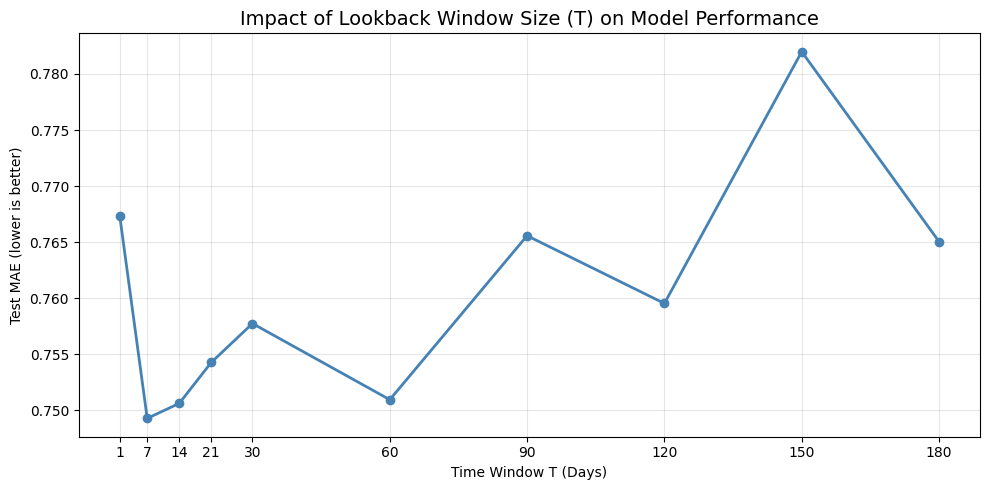


Sweep Summary:


In [22]:
# Define 10 window sizes spanning from 1 to 180 days
window_sizes = [1, 7, 14, 21, 30, 60, 90, 120, 150, 180]
sweep_results = []

print('=' * 80)
print(' TIME WINDOW (T) ITERATION SWEEP')
print('=' * 80)

for t in window_sizes:
    print(f'\nEvaluating lookback window T = {t} days...')

    # Create datasets with the current sequence length
    # All datasets can look back into earlier data for their input sequences
    sweep_train = CrimeGraphDataset(
        ts, chicago_tracts, edge_index, edge_weight,
        sequence_length=t, end_date='2023-11-01'
    )
    sweep_val = CrimeGraphDataset(
        ts, chicago_tracts, edge_index, edge_weight,
        sequence_length=t, start_date='2023-11-01', end_date='2023-12-01'
    )
    sweep_test = CrimeGraphDataset(
        ts, chicago_tracts, edge_index, edge_weight,
        sequence_length=t, start_date='2023-12-01'
    )

    # Create data loaders
    sweep_train_ld = PyGDataLoader(sweep_train, batch_size=1, shuffle=True, num_workers=0)
    sweep_val_ld = PyGDataLoader(sweep_val, batch_size=1, shuffle=False, num_workers=0)
    sweep_test_ld = PyGDataLoader(sweep_test, batch_size=1, shuffle=False, num_workers=0)

    # Train the ST-GCN-LSTM model with reduced epochs for the sweep
    sweep_model = STGCNLSTMRegressor(
        node_features=NUM_FEATURES, gcn_hidden=64,
        lstm_hidden=128, dropout=0.2, use_attention=True
    )
    sweep_model, _ = train_model(
        sweep_model, sweep_train_ld, sweep_val_ld, f'sweep_T{t}',
        epochs=15, lr=0.0005, patience=7, loss_fn='MSELoss'
    )

    # Evaluate on the test set
    sweep_criterion = nn.SmoothL1Loss()
    _, mae, rmse, r2, _, _ = evaluate(sweep_model, sweep_test_ld, sweep_criterion, device)
    print(f'  -> T={t}: MAE={mae:.4f}, RMSE={rmse:.4f}, R2={r2:.4f}')

    sweep_results.append({'T': t, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

# Plot the sweep results
sweep_df = pd.DataFrame(sweep_results)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sweep_df['T'], sweep_df['MAE'], marker='o', color='steelblue', linewidth=2)
ax.set_title('Impact of Lookback Window Size (T) on Model Performance', fontsize=14)
ax.set_xlabel('Time Window T (Days)')
ax.set_ylabel('Test MAE (lower is better)')
ax.set_xticks(window_sizes)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/time_window_sweep.png', dpi=150)
plt.show()

print('\nSweep Summary:')


---
## 15. ST-GCN-LSTM (Main Model)

All models share the same I/O contract:

| | Shape | Description |
|---|---|---|
| **Input x** | `[N, T, F]` | N nodes x T days x F features |
| **Input edge_index** | `[2, E]` | Graph edges in COO format |
| **Output** | `[N]` | Predicted crime count for each tract |

Uses 3 GAT layers + bidirectional LSTM. Trained with MSELoss instead of SmoothL1 to better capture high-crime areas.

In [20]:
class STGCNLSTMRegressor(nn.Module):
    """
    Spatio-Temporal Graph Convolutional Network with LSTM.
    Improved version: 3 spatial layers and MSELoss for better coverage of high-crime tracts.
    """

    def __init__(self, node_features, gcn_hidden=64, lstm_hidden=128,
                 dropout=0.3, use_attention=True):
        super().__init__()
        self.use_attention = use_attention

        # --- Spatial Layers (3 layers for 3-hop neighborhood) ---
        if use_attention:
            # GAT: multi-head attention aggregates neighbor features with learned weights
            self.spatial1 = GATConv(node_features, gcn_hidden, heads=2, concat=True, dropout=dropout)
            self.spatial2 = GATConv(gcn_hidden * 2, gcn_hidden, heads=2, concat=True, dropout=dropout)
            self.spatial3 = GATConv(gcn_hidden * 2, gcn_hidden, heads=1, concat=False, dropout=dropout)
            # LayerNorm dimensions match the concat output (hidden * heads)
            self.ln1 = nn.LayerNorm(gcn_hidden * 2)
            self.ln2 = nn.LayerNorm(gcn_hidden * 2)
        else:
            # Standard GCN fallback (no attention)
            self.spatial1 = GCNConv(node_features, gcn_hidden)
            self.spatial2 = GCNConv(gcn_hidden, gcn_hidden)
            self.spatial3 = GCNConv(gcn_hidden, gcn_hidden)
            self.ln1 = nn.LayerNorm(gcn_hidden)
            self.ln2 = nn.LayerNorm(gcn_hidden)

        self.ln3 = nn.LayerNorm(gcn_hidden)  # After the third spatial layer
        self.dropout_layer = nn.Dropout(dropout)

        # --- Temporal Layer ---
        # Bidirectional LSTM: processes the sequence of spatial encodings in both directions
        self.lstm = nn.LSTM(
            input_size=gcn_hidden,
            hidden_size=lstm_hidden,
            num_layers=2,
            bidirectional=True,
            batch_first=True,
            dropout=dropout
        )
        # Normalize the concatenated forward+backward hidden states
        self.ln_out = nn.LayerNorm(lstm_hidden * 2)

        # --- Regression Head ---
        self.fc1 = nn.Linear(lstm_hidden * 2, 64)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x, edge_index, edge_weight=None):
        seq_len = x.size(1)  # T = number of timesteps
        node_temporal = []

        # Process each timestep through the spatial layers
        for t in range(seq_len):
            xt = x[:, t, :]  # Features at timestep t: [N, F]

            # Layer 1: aggregate 1-hop neighbors
            if self.use_attention:
                h = F.elu(self.ln1(self.spatial1(xt, edge_index)))
            else:
                h = F.elu(self.ln1(self.spatial1(xt, edge_index, edge_weight)))
            h = self.dropout_layer(h)

            # Layer 2: aggregate 2-hop neighbors
            if self.use_attention:
                h = F.elu(self.ln2(self.spatial2(h, edge_index)))
            else:
                h = F.elu(self.ln2(self.spatial2(h, edge_index, edge_weight)))
            h = self.dropout_layer(h)

            # Layer 3: aggregate 3-hop neighbors
            if self.use_attention:
                h = F.elu(self.ln3(self.spatial3(h, edge_index)))
            else:
                h = F.elu(self.ln3(self.spatial3(h, edge_index, edge_weight)))

            node_temporal.append(h)  # h shape: [N, gcn_hidden]

        # Stack per-timestep spatial encodings: [T, N, gcn_hidden] -> [N, T, gcn_hidden]
        temporal_stack = torch.stack(node_temporal, dim=0).permute(1, 0, 2)

        # Bidirectional LSTM: captures both forward and backward temporal dynamics
        _, (hn, _) = self.lstm(temporal_stack)
        # hn shape: [num_layers * 2, N, lstm_hidden]
        # Concatenate the last forward (hn[-2]) and last backward (hn[-1]) hidden states
        final_hidden = self.ln_out(torch.cat([hn[-2], hn[-1]], dim=1))  # [N, lstm_hidden*2]

        # project to scalar prediction per node
        out = F.relu(self.fc1(self.dropout_layer(final_hidden)))
        out = self.fc2(out)
        return out.squeeze(-1)  # [N]


# Train the ST-GCN-LSTM with MSELoss (professor suggested exploring different loss functions)
stgcn_model = STGCNLSTMRegressor(
    node_features=NUM_FEATURES,
    gcn_hidden=64,
    lstm_hidden=128,
    dropout=0.2,
    use_attention=True
)

stgcn_model, stgcn_history = train_model(
    stgcn_model,
    train_loader,
    val_loader,
    'stgcn_lstm',
    epochs=100,
    lr=0.0005,
    patience=25,
    loss_fn='MSELoss'
)


Training: stgcn_lstm
Parameters: 637,249
Loss function: MSELoss


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch   1 | Train MAE: 0.7484 | Val MAE: 0.8709 | Val RMSE: 1.1453 | Val R2: 0.0998


Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

... (153 outputs left out)

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Training:   0%|          | 0/1004 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Early stopping at epoch 73
Best Val MAE: 0.7686


---
## 16. Test Set Evaluation & Deep Dive

Detailed evaluation of test set predictions:
1. **Single-Day Maps:** Actual vs Predicted vs Residuals for Dec 1, 2023
2. **Highest Crime Tract Time Series:** Actual vs Predicted over 31 test days
3. **Dual Metrics:** MSE, RMSE, R2 for the single day AND the full 31-day set

In [37]:
# Use the best-performing model for the deep dive evaluation
best_model_name = 'ST-GCN-LSTM'
best_model = stgcn_model
best_model.eval()

# Create test loader
test_loader = PyGDataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)

# Collect per-node, per-day predictions across the entire test set
test_results_list = []

with torch.no_grad():
    for i in range(len(test_dataset)):
        # Get the i-th test sample
        batch = test_dataset[i]
        x = batch.x.to(device)
        ei = batch.edge_index.to(device)
        ew = batch.edge_weight.to(device) if batch.edge_weight is not None else None


        preds = best_model(x, ei, ew).cpu().numpy()
        actuals = batch.y.numpy()

        # Map the valid_index to the actual date
        date_idx = test_dataset.valid_indices[i]
        date_val = test_dataset.dates[date_idx]

        # Store per-tract results
        for j, geoid in enumerate(test_dataset.sorted_tracts):
            test_results_list.append({
                'date': date_val,
                'GEOID': geoid,
                'actual': actuals[j],
                'predicted': preds[j],
                'residual': actuals[j] - preds[j]
            })

# Create DataFrame for analysis
results_df = pd.DataFrame(test_results_list)
print(f"Collected predictions: {len(results_df)} rows ({results_df['date'].nunique()} days x {results_df['GEOID'].nunique()} tracts)")

Collected predictions: 27218 rows (31 days x 878 tracts)


In [38]:
# --- DUAL METRICS REPORTING ---
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Select Dec 1, 2023 as the single-day benchmark
single_day = pd.Timestamp('2023-12-01')
day_df = results_df[results_df['date'] == single_day]

# Single-day metrics (Dec 1, 2023)
day_mse = mean_squared_error(day_df['actual'], day_df['predicted'])
day_rmse = np.sqrt(day_mse)
day_r2 = r2_score(day_df['actual'], day_df['predicted'])

# Full 31-day metrics (all of December 2023)
full_mse = mean_squared_error(results_df['actual'], results_df['predicted'])
full_rmse = np.sqrt(full_mse)
full_r2 = r2_score(results_df['actual'], results_df['predicted'])

print('=' * 60)
print(f' DUAL METRICS REPORTING ({best_model_name})')
print('=' * 60)
print(f'Single-Day ({single_day.date()}):')
print(f'  MSE:  {day_mse:.4f}')
print(f'  RMSE: {day_rmse:.4f}')
print(f'  R2:   {day_r2:.4f}')
print(f'\nFull 31-Day Test Set (Dec 2023):')
print(f'  MSE:  {full_mse:.4f}')
print(f'  RMSE: {full_rmse:.4f}')
print(f'  R2:   {full_r2:.4f}')

 DUAL METRICS REPORTING (ST-GCN-LSTM)
Single-Day (2023-12-01):
  MSE:  1.3876
  RMSE: 1.1780
  R2:   0.2457

Full 31-Day Test Set (Dec 2023):
  MSE:  1.0902
  RMSE: 1.0441
  R2:   0.1859


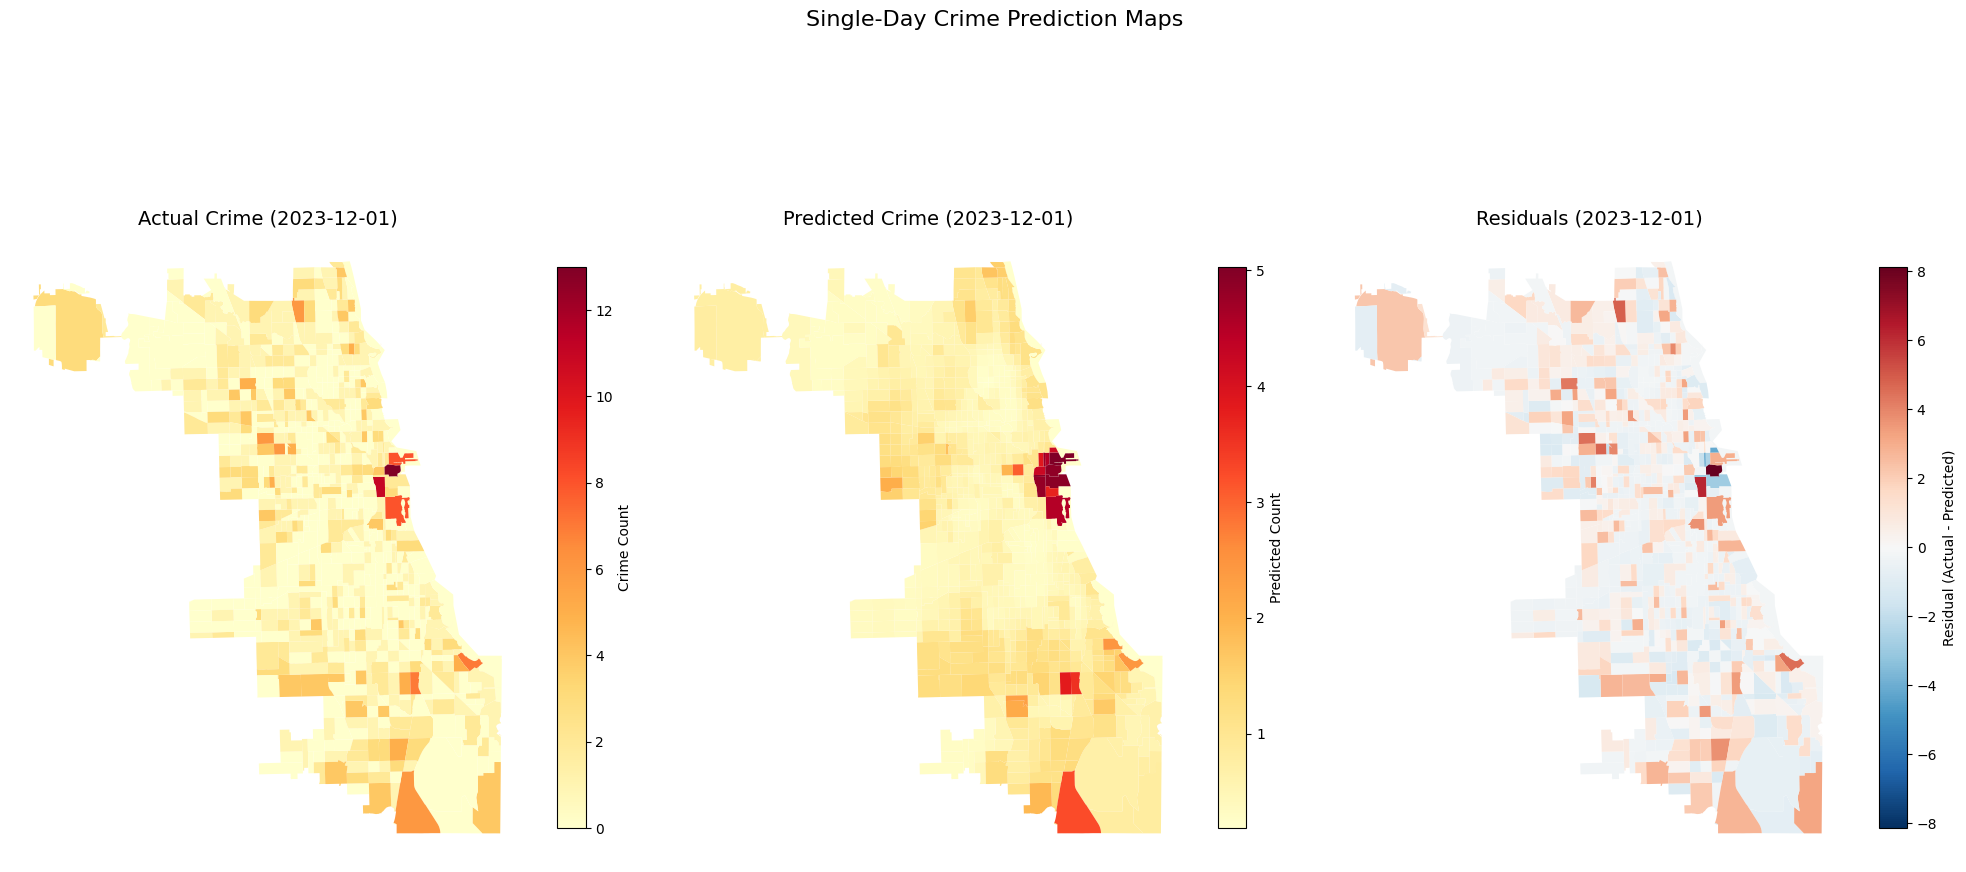

In [39]:
# --- THREE MAPS FOR A SINGLE DAY (Dec 1, 2023) ---
# Merge prediction data with census tract geometries for geographic plotting
day_df = results_df[results_df['date'] == single_day].copy()
map_data = chicago_tracts.merge(day_df, on='GEOID', how='left')

fig, axes = plt.subplots(1, 3, figsize=(20, 10))

# Map 1: Actual crime counts (ground truth)
map_data.plot(column='actual', cmap='YlOrRd', ax=axes[0], legend=True,
              legend_kwds={'shrink': 0.6, 'label': 'Crime Count'})
axes[0].set_title(f'Actual Crime ({single_day.date()})', fontsize=14)
axes[0].axis('off')

# Map 2: Predicted crime counts (model output)
map_data.plot(column='predicted', cmap='YlOrRd', ax=axes[1], legend=True,
              legend_kwds={'shrink': 0.6, 'label': 'Predicted Count'})
axes[1].set_title(f'Predicted Crime ({single_day.date()})', fontsize=14)
axes[1].axis('off')

# Map 3: Residuals (Predicted minus Actual) using a diverging colormap
# Red = under-predicted, Blue = over-predicted, White = accurate
vmax = max(abs(map_data['residual'].min()), abs(map_data['residual'].max()))
map_data.plot(column='residual', cmap='RdBu_r', ax=axes[2], legend=True,
              vmin=-vmax, vmax=vmax,
              legend_kwds={'shrink': 0.6, 'label': 'Residual (Actual - Predicted)'})
axes[2].set_title(f'Residuals ({single_day.date()})', fontsize=14)
axes[2].axis('off')

plt.suptitle('Single-Day Crime Prediction Maps', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('outputs/single_day_maps.png', dpi=200, bbox_inches='tight')
plt.show()

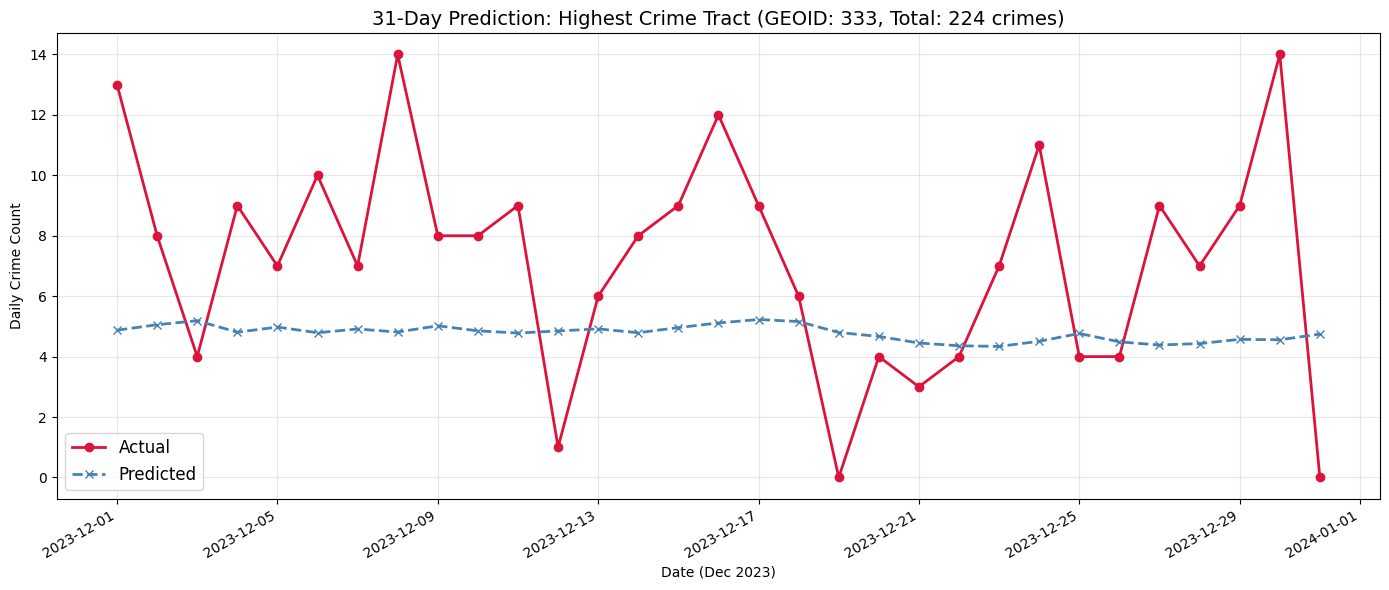

In [40]:
# --- TIME SERIES FOR HIGHEST CRIME TRACT ---
# Identify the census tract with the most total crime in the test period
tract_totals = results_df.groupby('GEOID')['actual'].sum()
highest_geoid = tract_totals.idxmax()
highest_total = tract_totals.max()

# Extract the 31-day time series for that single tract
tract_ts = results_df[results_df['GEOID'] == highest_geoid].sort_values('date')

fig, ax = plt.subplots(figsize=(14, 6))
# Plot actual values as solid line with circle markers
ax.plot(tract_ts['date'], tract_ts['actual'], marker='o', color='crimson',
        label='Actual', linewidth=2)
# Plot predicted values as dashed line with x markers
ax.plot(tract_ts['date'], tract_ts['predicted'], marker='x', color='steelblue',
        label='Predicted', linewidth=2, linestyle='--')

ax.set_title(f'31-Day Prediction: Highest Crime Tract (GEOID: {highest_geoid}, '
             f'Total: {highest_total:.0f} crimes)', fontsize=14)
ax.set_xlabel('Date (Dec 2023)')
ax.set_ylabel('Daily Crime Count')
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
fig.autofmt_xdate()  # Rotate date labels for readability
plt.tight_layout()
plt.savefig('outputs/highest_tract_timeseries.png', dpi=200)
plt.show()

In [41]:
# --- FULL MODEL COMPARISON ON TEST SET ---
criterion = nn.SmoothL1Loss()

models = {
    'GCN': gcn_model,
    'LSTM': lstm_model,
    'CNN': cnn_model,
    'CNN+LSTM': cnn_lstm_model,
    'ST-GCN-LSTM': stgcn_model
}

# Evaluate each model on the test set
comparison = {}
for name, m in models.items():
    _, mae, rmse, r2, _, _ = evaluate(m, test_loader, criterion, device)
    comparison[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}
    print(f'{name:15s} | MAE: {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}')

# Display comparison table
comp_df = pd.DataFrame(comparison).T.round(4)
print('\n' + comp_df.to_string())

Evaluating:   0%|          | 0/31 [00:00<?, ?it/s]

GCN             | MAE: 0.7521 | RMSE: 1.0965 | R2: 0.1023


Evaluating:   0%|          | 0/31 [00:00<?, ?it/s]

LSTM            | MAE: 0.6613 | RMSE: 0.9561 | R2: 0.3173


Evaluating:   0%|          | 0/31 [00:00<?, ?it/s]

CNN             | MAE: 0.6673 | RMSE: 0.9491 | R2: 0.3273


Evaluating:   0%|          | 0/31 [00:00<?, ?it/s]

CNN+LSTM        | MAE: 0.6637 | RMSE: 0.9498 | R2: 0.3264


Evaluating:   0%|          | 0/31 [00:00<?, ?it/s]

ST-GCN-LSTM     | MAE: 0.7456 | RMSE: 1.0441 | R2: 0.1859

                MAE    RMSE      R2
GCN          0.7521  1.0965  0.1023
LSTM         0.6613  0.9561  0.3173
CNN          0.6673  0.9491  0.3273
CNN+LSTM     0.6637  0.9498  0.3264
ST-GCN-LSTM  0.7456  1.0441  0.1859


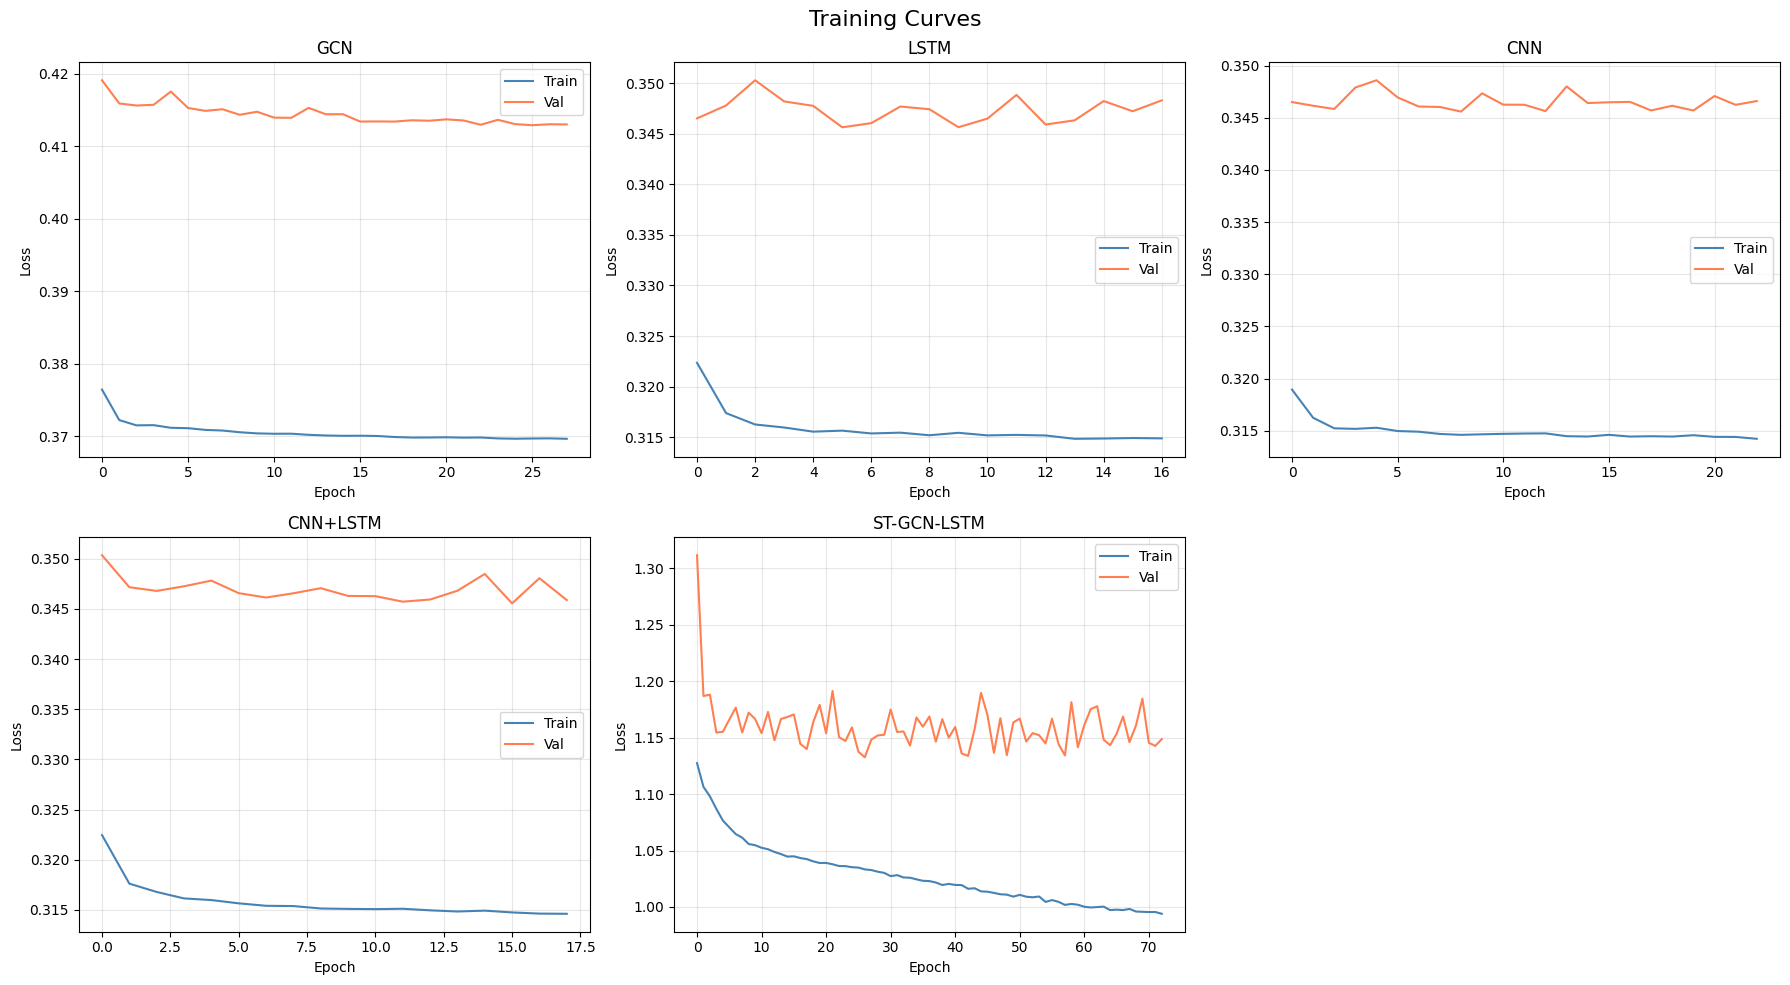

In [42]:
# --- TRAINING CURVES ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
histories = {
    'GCN': gcn_history, 'LSTM': lstm_history, 'CNN': cnn_history,
    'CNN+LSTM': cnn_lstm_history, 'ST-GCN-LSTM': stgcn_history
}

for ax, (name, hist) in zip(axes.flat, histories.items()):
    ax.plot(hist['train_loss'], label='Train', color='steelblue')
    ax.plot(hist['val_loss'], label='Val', color='coral')
    ax.set_title(f'{name}', fontsize=12)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(alpha=0.3)

# Hide the unused 6th subplot
axes[1, 2].axis('off')
plt.suptitle('Training Curves', fontsize=16)
plt.tight_layout()
plt.savefig('outputs/training_curves.png', dpi=150)
plt.show()

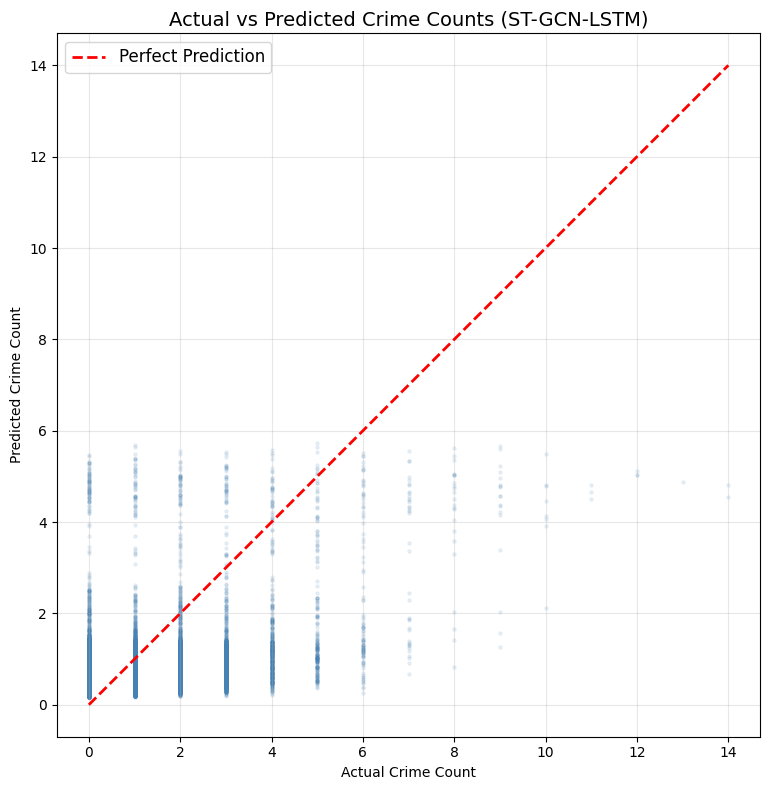

In [43]:
# --- SCATTER PLOT: ACTUAL vs PREDICTED (all test days) ---
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(results_df['actual'], results_df['predicted'],
           alpha=0.1, s=5, color='steelblue')

# Perfect prediction reference line
max_val = max(results_df['actual'].max(), results_df['predicted'].max())
ax.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect Prediction')

ax.set_title(f'Actual vs Predicted Crime Counts ({best_model_name})', fontsize=14)
ax.set_xlabel('Actual Crime Count')
ax.set_ylabel('Predicted Crime Count')
ax.legend(fontsize=12)
ax.set_aspect('equal')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/scatter_actual_vs_predicted.png', dpi=200)
plt.show()

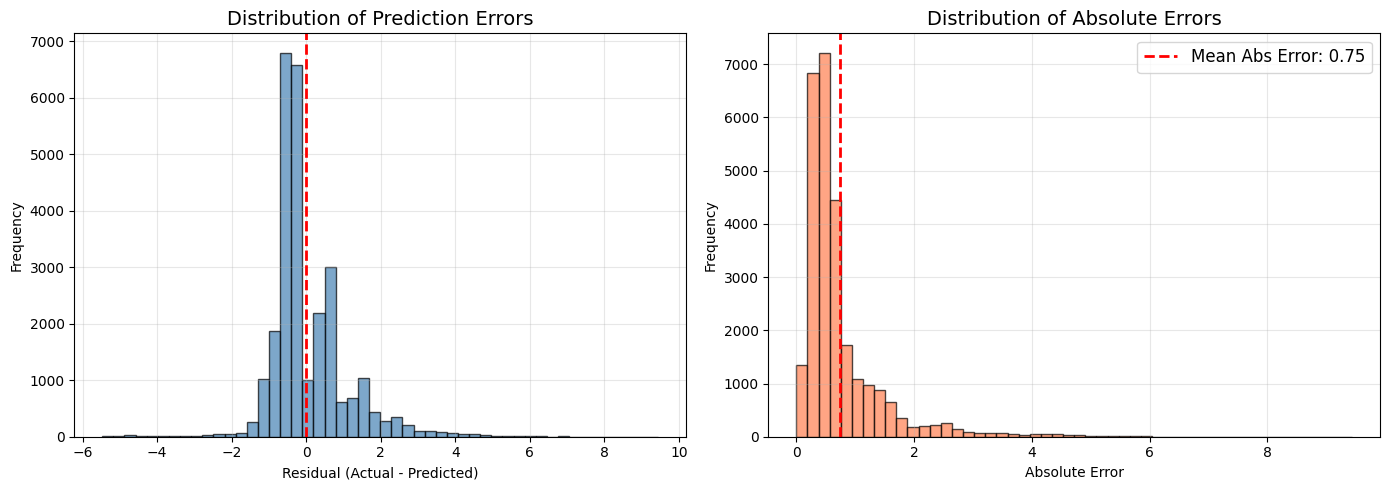

In [44]:
# --- ERROR DISTRIBUTION: Histogram of Residuals ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: residual distribution
axes[0].hist(results_df['residual'], bins=50, color='steelblue',
             edgecolor='black', alpha=0.7)
axes[0].axvline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Distribution of Prediction Errors', fontsize=14)
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].set_ylabel('Frequency')
axes[0].grid(alpha=0.3)

# Right: absolute error distribution
abs_errors = results_df['residual'].abs()
axes[1].hist(abs_errors, bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[1].axvline(abs_errors.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean Abs Error: {abs_errors.mean():.2f}')
axes[1].set_title('Distribution of Absolute Errors', fontsize=14)
axes[1].set_xlabel('Absolute Error')
axes[1].set_ylabel('Frequency')
axes[1].legend(fontsize=12)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/error_distribution.png', dpi=200)
plt.show()

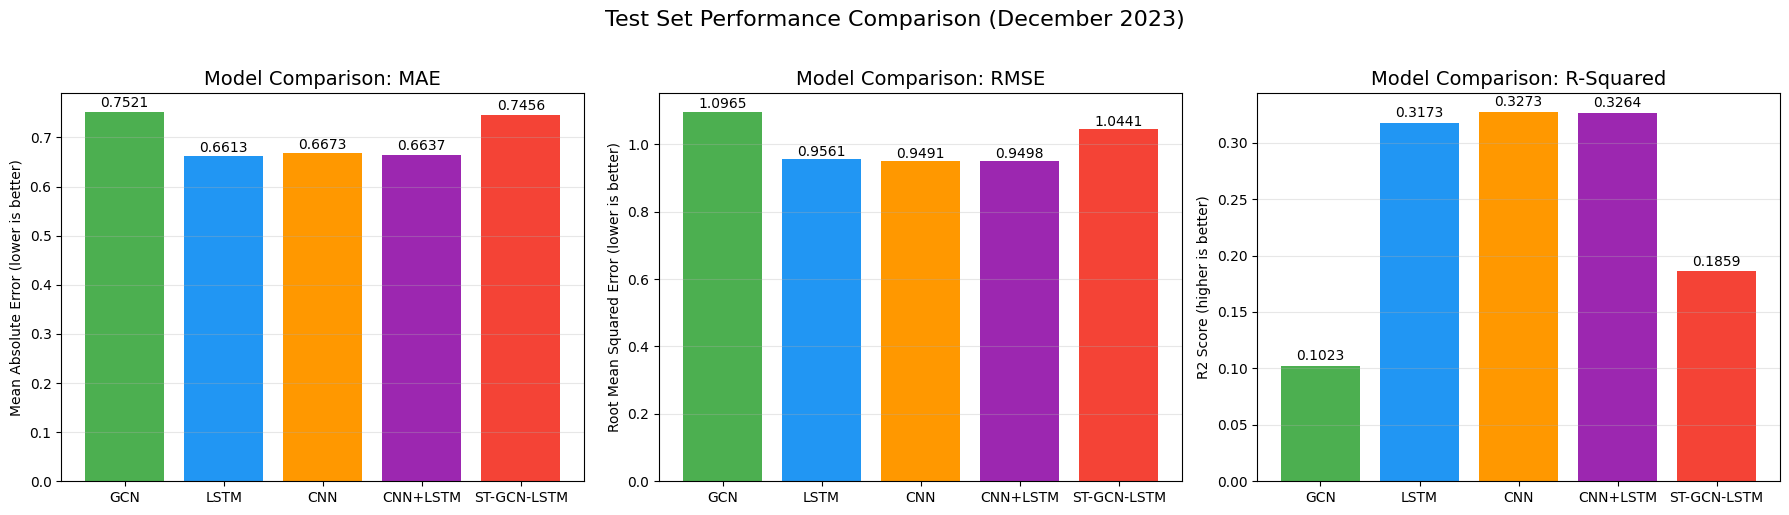

In [45]:
# --- MODEL COMPARISON BAR CHART ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_names = list(comparison.keys())
colors = ['#4CAF50', '#2196F3', '#FF9800', '#9C27B0', '#F44336']

# MAE comparison
mae_vals = [comparison[m]['MAE'] for m in model_names]
axes[0].bar(model_names, mae_vals, color=colors)
axes[0].set_title('Model Comparison: MAE', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (lower is better)')
for j, v in enumerate(mae_vals):
    axes[0].text(j, v + 0.01, f'{v:.4f}', ha='center', fontsize=10)
axes[0].grid(alpha=0.3, axis='y')

# RMSE comparison
rmse_vals = [comparison[m]['RMSE'] for m in model_names]
axes[1].bar(model_names, rmse_vals, color=colors)
axes[1].set_title('Model Comparison: RMSE', fontsize=14)
axes[1].set_ylabel('Root Mean Squared Error (lower is better)')
for j, v in enumerate(rmse_vals):
    axes[1].text(j, v + 0.01, f'{v:.4f}', ha='center', fontsize=10)
axes[1].grid(alpha=0.3, axis='y')

# R2 comparison
r2_vals = [comparison[m]['R2'] for m in model_names]
axes[2].bar(model_names, r2_vals, color=colors)
axes[2].set_title('Model Comparison: R-Squared', fontsize=14)
axes[2].set_ylabel('R2 Score (higher is better)')
for j, v in enumerate(r2_vals):
    axes[2].text(j, v + 0.005, f'{v:.4f}', ha='center', fontsize=10)
axes[2].grid(alpha=0.3, axis='y')

plt.suptitle('Test Set Performance Comparison (December 2023)', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('outputs/model_comparison_bars.png', dpi=200, bbox_inches='tight')
plt.show()

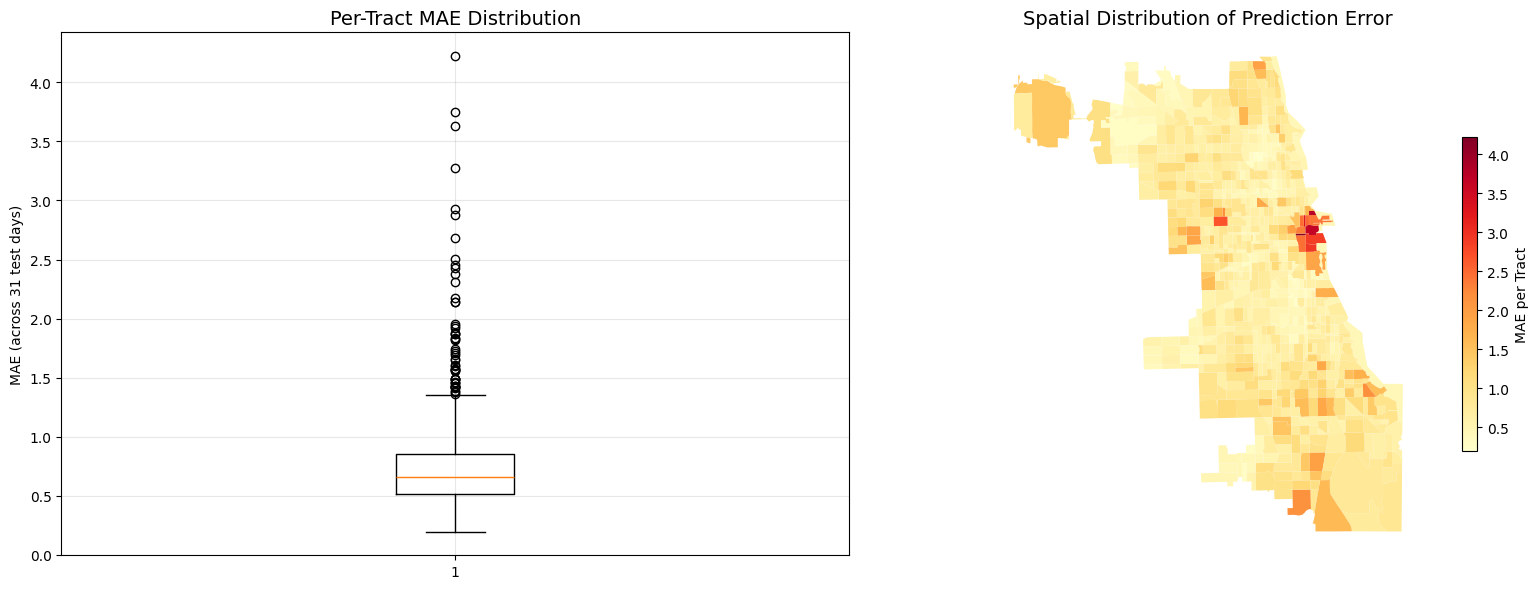

In [46]:
# --- PER-TRACT ERROR ANALYSIS ---
# Compute MAE for each tract across the entire test period
tract_mae = results_df.groupby('GEOID').apply(
    lambda g: mean_absolute_error(g['actual'], g['predicted'])
).reset_index(name='tract_mae')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: boxplot of per-tract MAE
axes[0].boxplot(tract_mae['tract_mae'], vert=True)
axes[0].set_title('Per-Tract MAE Distribution', fontsize=14)
axes[0].set_ylabel('MAE (across 31 test days)')
axes[0].grid(alpha=0.3)

# Right: geographic map of per-tract MAE
map_mae = chicago_tracts.merge(tract_mae, on='GEOID', how='left')
map_mae.plot(column='tract_mae', cmap='YlOrRd', ax=axes[1], legend=True,
             legend_kwds={'shrink': 0.6, 'label': 'MAE per Tract'})
axes[1].set_title('Spatial Distribution of Prediction Error', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.savefig('outputs/per_tract_error.png', dpi=200)
plt.show()

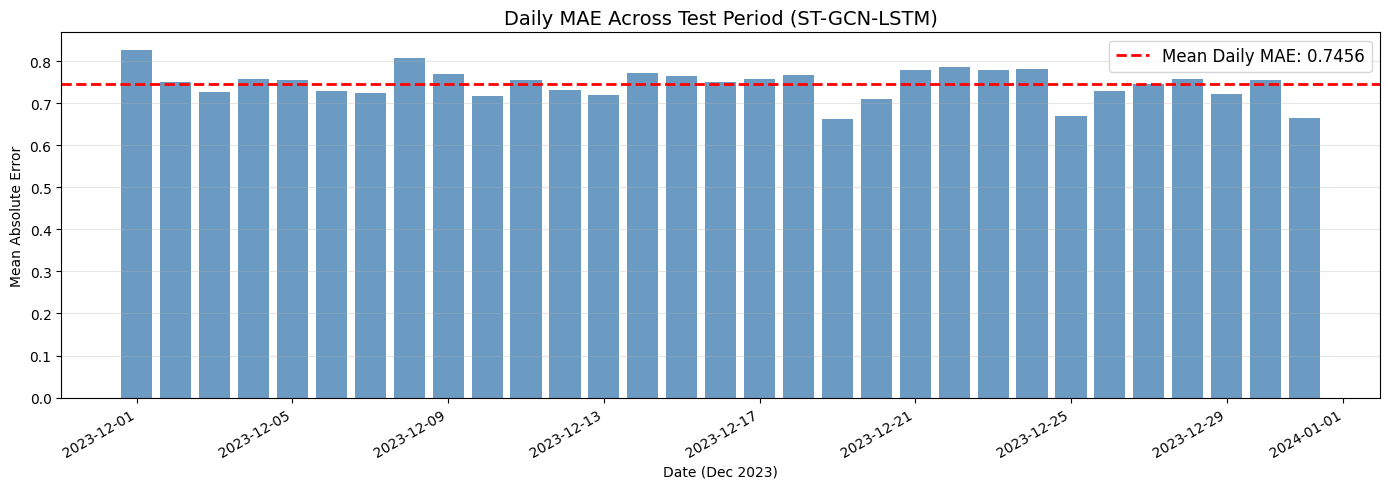

In [47]:
# --- DAILY MAE OVER THE TEST PERIOD ---
daily_mae = results_df.groupby('date').apply(
    lambda g: mean_absolute_error(g['actual'], g['predicted'])
).reset_index(name='daily_mae')

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(daily_mae['date'], daily_mae['daily_mae'], color='steelblue', alpha=0.8)
ax.axhline(daily_mae['daily_mae'].mean(), color='red', linestyle='--',
           linewidth=2, label=f'Mean Daily MAE: {daily_mae["daily_mae"].mean():.4f}')
ax.set_title(f'Daily MAE Across Test Period ({best_model_name})', fontsize=14)
ax.set_xlabel('Date (Dec 2023)')
ax.set_ylabel('Mean Absolute Error')
ax.legend(fontsize=12)
ax.grid(alpha=0.3, axis='y')
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('outputs/daily_mae_timeline.png', dpi=200)
plt.show()

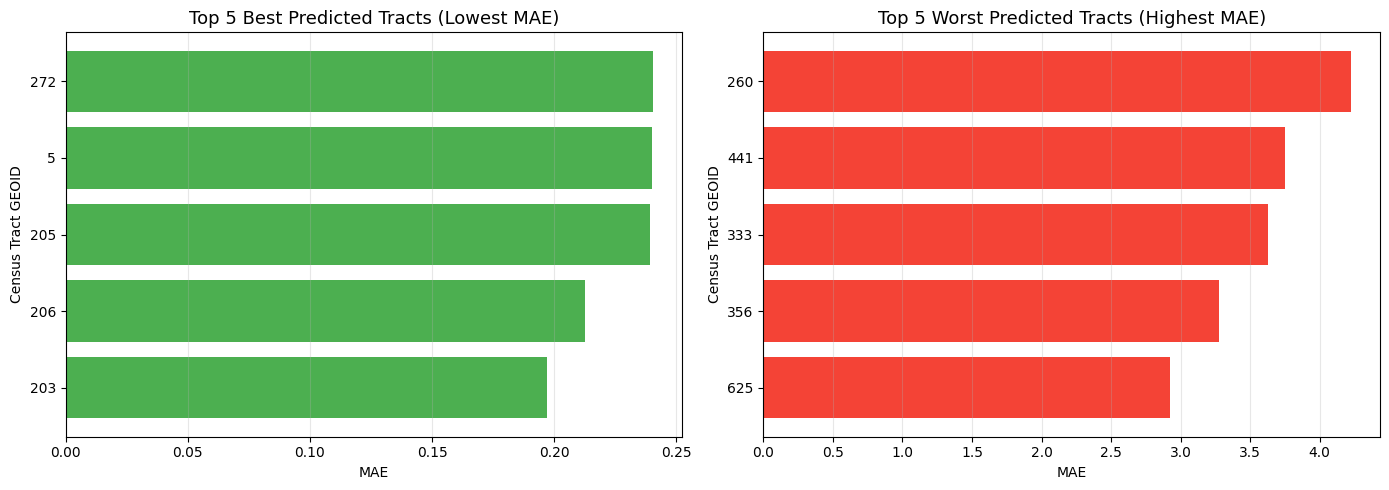

In [48]:
# --- TOP 5 AND BOTTOM 5 TRACTS BY PREDICTION ACCURACY ---
tract_mae_sorted = tract_mae.sort_values('tract_mae')
top5 = tract_mae_sorted.head(5)   # Best predicted tracts
bot5 = tract_mae_sorted.tail(5)    # Worst predicted tracts

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(top5['GEOID'], top5['tract_mae'], color='#4CAF50')
axes[0].set_title('Top 5 Best Predicted Tracts (Lowest MAE)', fontsize=13)
axes[0].set_xlabel('MAE')
axes[0].set_ylabel('Census Tract GEOID')
axes[0].grid(alpha=0.3, axis='x')

axes[1].barh(bot5['GEOID'], bot5['tract_mae'], color='#F44336')
axes[1].set_title('Top 5 Worst Predicted Tracts (Highest MAE)', fontsize=13)
axes[1].set_xlabel('MAE')
axes[1].set_ylabel('Census Tract GEOID')
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('outputs/best_worst_tracts.png', dpi=200)
plt.show()

## 17. Summary

In [49]:
print('=' * 80)
print('PROJECT SUMMARY')
print('=' * 80)
print(f'\nData:')
print(f'  Census Tracts:  {NUM_NODES}')
print(f'  Time Period:    2021-2023 (daily)')
print(f'  Features:       {NUM_FEATURES} (crime_count)')
print(f'  Train / Val / Test: {len(train_dataset)} / {len(val_dataset)} / {len(test_dataset)}')
print(f'\nTime Window Sweep (10 values tested):')
print(sweep_df.to_string(index=False))
print(f'\nTest Set Results (December 2023):')
for name, res in comparison.items():
    print(f"  {name:15s}: MAE={res['MAE']:.4f}, RMSE={res['RMSE']:.4f}, R2={res['R2']:.4f}")
print(f'\nSingle-Day vs Full-Month ({best_model_name}):')
print(f'  Dec 1 only:   MSE={day_mse:.4f}, RMSE={day_rmse:.4f}, R2={day_r2:.4f}')
print(f'  Full Dec:     MSE={full_mse:.4f}, RMSE={full_rmse:.4f}, R2={full_r2:.4f}')
print(f'\nAll models use I/O contract: [N={NUM_NODES}, T={SEQ_LEN}, F={NUM_FEATURES}] -> [N={NUM_NODES}]')
print('\n' + '=' * 80)
print('COMPLETE')
print('=' * 80)

PROJECT SUMMARY

Data:
  Census Tracts:  878
  Time Period:    2021-2023 (daily)
  Features:       1 (crime_count)
  Train / Val / Test: 1004 / 30 / 31

Time Window Sweep (10 values tested):
  T      MAE     RMSE       R2
  1 0.767339 1.086025 0.119242
  7 0.749283 1.042228 0.188847
 14 0.750622 1.036355 0.197962
 21 0.754275 1.046156 0.182722
 30 0.757745 1.033629 0.202177
 60 0.750950 1.025775 0.214256
 90 0.765576 1.028148 0.210616
120 0.759535 1.038510 0.194624
150 0.781988 1.060405 0.160307
180 0.765048 1.028934 0.209409

Test Set Results (December 2023):
  GCN            : MAE=0.7521, RMSE=1.0965, R2=0.1023
  LSTM           : MAE=0.6613, RMSE=0.9561, R2=0.3173
  CNN            : MAE=0.6673, RMSE=0.9491, R2=0.3273
  CNN+LSTM       : MAE=0.6637, RMSE=0.9498, R2=0.3264
  ST-GCN-LSTM    : MAE=0.7456, RMSE=1.0441, R2=0.1859

Single-Day vs Full-Month (ST-GCN-LSTM):
  Dec 1 only:   MSE=1.3876, RMSE=1.1780, R2=0.2457
  Full Dec:     MSE=1.0902, RMSE=1.0441, R2=0.1859

All models use I/O 